In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from preprocessing import preprocess_audio
from wavelet_features import extract_wavelet_features

In [2]:
import numpy as np
import pandas as pd

df = pd.read_csv(
    PROJECT_ROOT / "outputs/features/handcrafted_features.csv"
)

metadata_cols = [
    "sample_id", "trial_id", "actor_id",
    "emotion_label", "split"
]

feature_cols = [
    col for col in df.columns
    if col not in metadata_cols
]

print("Dataset shape:", df.shape)
print("Feature matrix:", df[feature_cols].shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate sample IDs:", df["sample_id"].duplicated().sum())

print("\nFeature group dimensions:")
print("Time:", sum(c.startswith(("zcr_", "rms_", "energy_"))
                   for c in feature_cols))
print("Spectral:", sum(c.startswith("spectral_")
                       for c in feature_cols))
print("DWT:", sum(c.startswith("dwt_")
                  for c in feature_cols))

print("\nSplit distribution:")
print(df["split"].value_counts())

assert df.shape == (1440, 53)
assert np.isfinite(df[feature_cols].to_numpy()).all()
assert df["sample_id"].is_unique
assert df["trial_id"].is_unique
assert df["split"].value_counts().to_dict() == {
    "train": 960, "val": 240, "test": 240
}

print("\nAll combined feature checks passed!")

Dataset shape: (1440, 53)
Feature matrix: (1440, 48)
Missing values: 0
Duplicate sample IDs: 0

Feature group dimensions:
Time: 12
Spectral: 16
DWT: 20

Split distribution:
split
train    960
test     240
val      240
Name: count, dtype: int64

All combined feature checks passed!


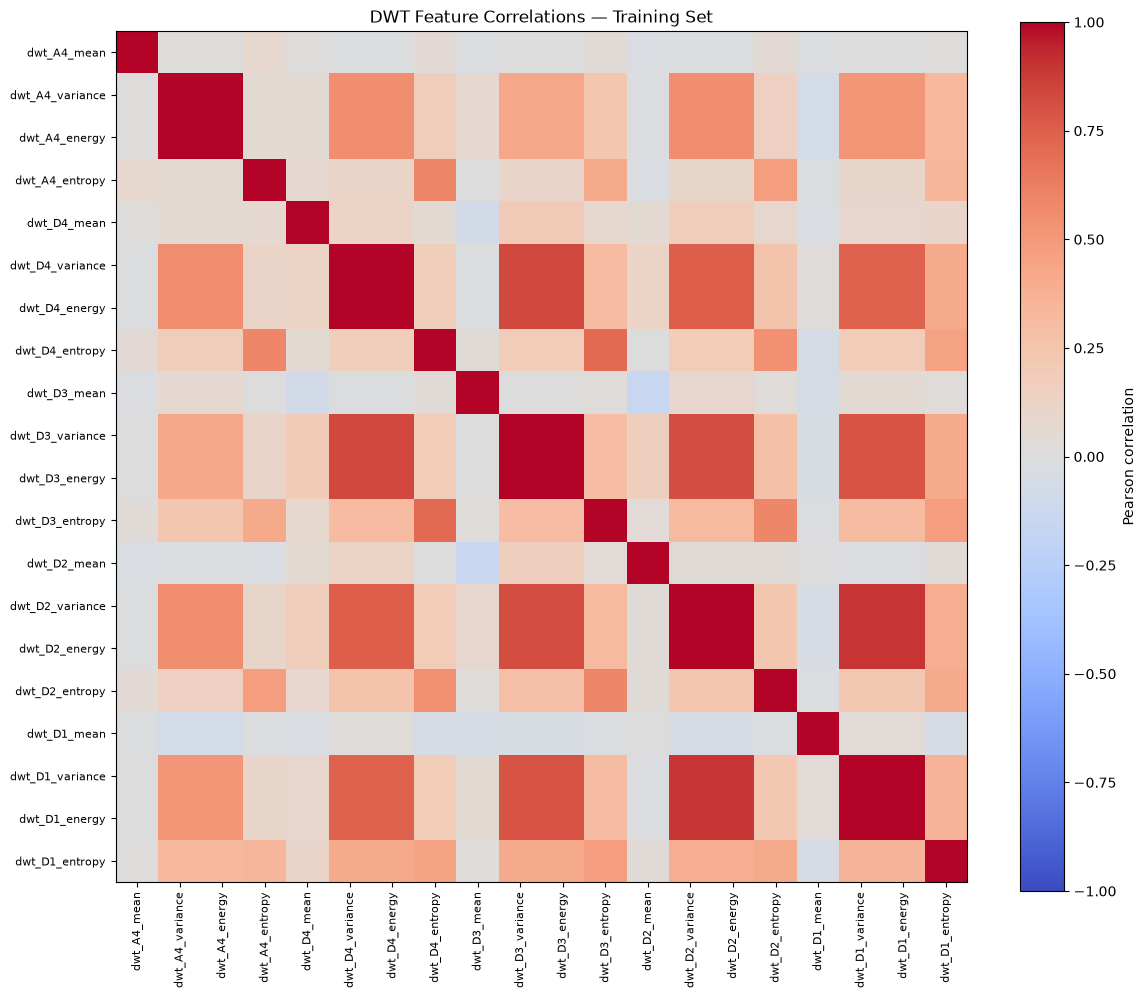

In [3]:
import matplotlib.pyplot as plt

dwt_cols = [c for c in feature_cols if c.startswith("dwt_")]

corr = df.loc[df["split"] == "train", dwt_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(dwt_cols)))
ax.set_yticks(range(len(dwt_cols)))
ax.set_xticklabels(dwt_cols, rotation=90, fontsize=8)
ax.set_yticklabels(dwt_cols, fontsize=8)

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("DWT Feature Correlations — Training Set")

plt.tight_layout()
plt.show()

In [4]:
for level in ["A4", "D4", "D3", "D2", "D1"]:
    variance_col = f"dwt_{level}_variance"
    energy_col = f"dwt_{level}_energy"

    correlation = corr.loc[variance_col, energy_col]

    print(f"{level}: {correlation:.6f}")

A4: 1.000000
D4: 1.000000
D3: 1.000000
D2: 1.000000
D1: 1.000000


In [5]:
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .loc[lambda x: x.abs() >= 0.95]
    .sort_values(ascending=False)
)

display(high_corr)

dwt_D1_variance  dwt_D1_energy    1.0
dwt_D2_variance  dwt_D2_energy    1.0
dwt_D3_variance  dwt_D3_energy    1.0
dwt_A4_variance  dwt_A4_energy    1.0
dwt_D4_variance  dwt_D4_energy    1.0
dtype: float64

Pearson correlation analysis of the handcrafted DWT features revealed strong positive correlations between coefficient variance and mean squared energy within each decomposition level. This relationship is mathematically expected because mean squared energy equals variance plus squared mean. Additional correlations were observed among energy-related features across wavelet decomposition levels. These findings motivated an experimental comparison between the full DWT representation and a reduced representation excluding redundant energy features.

In [6]:
for level in ["A4", "D4", "D3", "D2", "D1"]:
    mean = df[f"dwt_{level}_mean"]
    variance = df[f"dwt_{level}_variance"]
    energy = df[f"dwt_{level}_energy"]

    difference = energy - (variance + mean**2)

    print(
        f"{level}: "
        f"Maximum absolute difference = "
        f"{difference.abs().max():.12e}"
    )

A4: Maximum absolute difference = 9.595189226497e-17
D4: Maximum absolute difference = 1.110223024625e-16
D3: Maximum absolute difference = 9.481347998386e-17
D2: Maximum absolute difference = 9.128982292328e-17
D1: Maximum absolute difference = 9.898765834793e-17
